# Agent-Based Models in Finance --- Companion Notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wulinsuo/AI-in-Finance/blob/main/notebooks/chapter20.ipynb)

Reproduces every worked numerical example in Chapter 20, `chapter20.tex`.

---

**© 2026 Wulin Suo. All rights reserved, except as the repository's [LICENSE](https://github.com/wulinsuo/AI-in-Finance/blob/main/LICENSE) allows:** you may view this notebook, download a copy for your own personal study, and run it on your own computer for that purpose. Any other reproduction, distribution, or derivative use needs the author's prior written permission (including use in teaching). Contact: Wulin.Suo@Queensu.ca

In [1]:
# Setup for Google Colab. Run locally, this cell does nothing: install the pinned
# packages once instead, with  python -m pip install -r requirements.txt
import sys
if "google.colab" in sys.modules:
    import subprocess, urllib.request
    _req_url = "https://raw.githubusercontent.com/wulinsuo/AI-in-Finance/main/requirements.txt"
    _reqs = [_line.split("#")[0].strip() for _line in urllib.request.urlopen(_req_url).read().decode().splitlines()]
    _reqs = [_r for _r in _reqs if _r and _r.split("==")[0] not in ("nbformat", "nbclient", "ipykernel")]
    if subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_reqs]).returncode == 0:
        print("Installed the package versions in requirements.txt. If Colab asks you to restart "
              "the session, restart it and run the notebook again from the top.")
    else:
        print("Could not install the pinned versions; continuing with Colab's own packages, "
              "so a few printed numbers may differ in the last digits from the book.")

## Worked Example 1: Zero-Intelligence Double Auction

Reproduces the hand-worked round of Section 20.1.2: two buyers who value the good at \$52 and \$48, two sellers whose costs are \$45 and \$50, and one round of random bids (\$50, \$30) and asks (\$47, \$65). Sorting bids from high to low and asks from low to high and matching them pairwise, only the top pair trades, at the midpoint price of \$48.50. Look at the realized surplus: it equals the efficient surplus of \$7.00, because the random matching happened to pair the high-value buyer with the low-cost seller, even though no trader knew anything about anyone else.

In [2]:
# True valuations and costs
V_B1, V_B2 = 52.0, 48.0
C_S1, C_S2 = 45.0, 50.0

efficient_surplus = (V_B1 - C_S1)
print('Efficient allocation surplus (buyer1-seller1):', efficient_surplus)

# One simulated round of zero-intelligence random bids/asks
b1, b2 = 50.0, 30.0
a1, a2 = 47.0, 65.0

bids = sorted([b1, b2], reverse=True)
asks = sorted([a1, a2])
print('Bids (descending):', bids)
print('Asks (ascending):', asks)

trades = []
for bid, ask in zip(bids, asks):
    if bid >= ask:
        trades.append((bid, ask))
print('Trades (bid, ask):', trades)

trade_price = (b1 + a1) / 2
print('Transaction price (midpoint):', trade_price)
print('Realized surplus (true valuations):', V_B1 - C_S1)

Efficient allocation surplus (buyer1-seller1): 7.0
Bids (descending): [50.0, 30.0]
Asks (ascending): [47.0, 65.0]
Trades (bid, ask): [(50.0, 47.0)]
Transaction price (midpoint): 48.5
Realized surplus (true valuations): 7.0


### Supplementary: Is a Single Random Round Reliable?
The hand-worked example above used one particular random draw that happened to select the efficient pair. Reusable function version, plus two checks: (1) does the same seed used in the chapter text reproduce that exact outcome, and (2) how reliable is a *single* simultaneous-clearing round, averaged over many independent trials, at capturing the efficient surplus?

The first cell is the code printed in Section 20.1.3; with `seed=2` it reproduces the chapter's trade at a price of about \$48.91 and a surplus of \$7.00. The second cell goes beyond the chapter: over 10,000 independent rounds, a single round captures on average only 0.91% of the efficient surplus, and reaches the full \$7.00 in just 0.83% of trials. The efficiency Gode and Sunder found comes from repeated, continuous trading, not from one lucky simultaneous round.

In [3]:
import random

def zero_intelligence_round(buyers, sellers, seed=None):
    rng = random.Random(seed)
    bids = [(rng.uniform(0, v), v) for v in buyers]
    asks = [(rng.uniform(c, 100), c) for c in sellers]
    bids.sort(key=lambda x: -x[0])
    asks.sort(key=lambda x: x[0])
    trades = []
    for (bid, val), (ask, cost) in zip(bids, asks):
        if bid >= ask:
            trades.append({'price': (bid + ask) / 2, 'surplus': val - cost})
    return trades

trades = zero_intelligence_round(buyers=[52.0, 48.0], sellers=[45.0, 50.0], seed=2)
print(trades)

[{'price': 48.912053681607716, 'surplus': 7.0}]


In [4]:
import numpy as np

zi_rng = np.random.default_rng(7)
V_B1, V_B2 = 52.0, 48.0
C_S1, C_S2 = 45.0, 50.0
efficient_surplus = V_B1 - C_S1

n_trials = 10000
captured = []
for _ in range(n_trials):
    b1 = zi_rng.uniform(0, V_B1)
    b2 = zi_rng.uniform(0, V_B2)
    a1 = zi_rng.uniform(C_S1, 100)
    a2 = zi_rng.uniform(C_S2, 100)
    buyers = sorted([(b1, V_B1), (b2, V_B2)], key=lambda x: -x[0])
    sellers = sorted([(a1, C_S1), (a2, C_S2)], key=lambda x: x[0])
    total_surplus = 0.0
    for (bid, val), (ask, cost) in zip(buyers, sellers):
        if bid >= ask:
            total_surplus += (val - cost)
    captured.append(total_surplus)

captured = np.array(captured)
print('Mean realized surplus over', n_trials, 'single-shot trials:', round(captured.mean(), 4))
print('Efficient surplus:', efficient_surplus)
print('Average efficiency captured (%):', round(100*captured.mean()/efficient_surplus, 2))
print('Fraction of trials reaching full efficient surplus:', round(np.mean(captured==efficient_surplus), 4))

Mean realized surplus over 10000 single-shot trials: 0.0637
Efficient surplus: 7.0
Average efficiency captured (%): 0.91
Fraction of trials reaching full efficient surplus: 0.0083


## Worked Example 2: Fundamentalist-Chartist Price Dynamics

Reproduces both scenarios of Section 20.1.4, with fundamental value $p_f = 100$, $\alpha = 0.3$, $\beta = 1.0$, $\lambda = 1.5$, and starting prices of 93 and 95. The first cell is Scenario A, a fundamentalist-dominated market ($n_f = 0.8$, $n_c = 0.2$): compare each line with the chapter's table, and note that the price closes in on 100 (97.400, 99.056, 99.893) as the fundamentalists' pull outweighs the chartists' push. The second cell is Scenario B, chartists only: the period changes grow from 3.000 to 4.500 to 6.750 and the price reaches 109.25, a self-reinforcing bubble.

In [5]:
p_f = 100.0
alpha = 0.3
beta = 1.0
lam = 1.5

def step(p_prev, p_prev2, nf, nc):
    d_f = alpha * (p_f - p_prev)
    d_c = beta * (p_prev - p_prev2)
    agg = nf * d_f + nc * d_c
    p_new = p_prev + lam * agg
    return p_new, d_f, d_c, agg

print('--- Scenario A: fundamentalist-dominated (n_f=0.8, n_c=0.2) ---')
p_prev2, p_prev = 93.0, 95.0
nf, nc = 0.8, 0.2
for t in range(3):
    p_new, d_f, d_c, agg = step(p_prev, p_prev2, nf, nc)
    print(f't={t}: p_t={p_prev:.3f}  d_f={d_f:.3f}  d_c={d_c:.3f}  agg={agg:.3f}  p_t+1={p_new:.3f}')
    p_prev2, p_prev = p_prev, p_new

--- Scenario A: fundamentalist-dominated (n_f=0.8, n_c=0.2) ---
t=0: p_t=95.000  d_f=1.500  d_c=2.000  agg=1.600  p_t+1=97.400
t=1: p_t=97.400  d_f=0.780  d_c=2.400  agg=1.104  p_t+1=99.056
t=2: p_t=99.056  d_f=0.283  d_c=1.656  agg=0.558  p_t+1=99.893


In [6]:
print('--- Scenario B: pure chartist, no fundamentalists (n_f=0.0, n_c=1.0) ---')
p_prev2, p_prev = 93.0, 95.0
nf, nc = 0.0, 1.0
for t in range(3):
    p_new, d_f, d_c, agg = step(p_prev, p_prev2, nf, nc)
    print(f't={t}: p_t={p_prev:.3f}  p_t+1={p_new:.3f}  (period change = {p_new - p_prev:.3f})')
    p_prev2, p_prev = p_prev, p_new

--- Scenario B: pure chartist, no fundamentalists (n_f=0.0, n_c=1.0) ---
t=0: p_t=95.000  p_t+1=98.000  (period change = 3.000)
t=1: p_t=98.000  p_t+1=102.500  (period change = 4.500)
t=2: p_t=102.500  p_t+1=109.250  (period change = 6.750)


## Emergent Stylized Facts: A Regime-Switching Simulation

Extends the fundamentalist-chartist model to 500 periods with two regimes: a calm, fundamentalist-heavy regime and a volatile, chartist-heavy regime. As a simple proxy for the performance-based switching Brock and Hommes formalize, the market switches into the volatile regime whenever the most recent price move exceeds a threshold (a large recent move is exactly the situation in which a chartist strategy would just have outperformed a fundamentalist one), and reverts to the calm regime otherwise.

This is the simulation of Section 20.2.1 (seed 42, threshold 0.25, $\beta = 1.1$, $\lambda = 1.0$). Look at the three numbers the chapter quotes: a variance ratio of 6.14 between the volatile and the calm regime, a Pearson kurtosis of 4.67 against the Gaussian 3.0 (fat tails), and an autocorrelation of squared returns of 0.658 at lag one (volatility clustering). None of them was put into the model; they emerge from two fixed rules switching in and out of dominance.

In [7]:
import numpy as np
from scipy import stats

vc_rng = np.random.default_rng(42)

p_f = 100.0
alpha = 0.3
beta_switch = 1.1
lam_switch = 1.0

nf_calm, nc_calm = 0.85, 0.15
nf_vol, nc_vol = 0.25, 0.75
sigma_calm = 0.15
sigma_vol = 0.50
switch_threshold = 0.25

T = 500
prices = [95.0, 95.0]
regimes = []

for t in range(2, T + 2):
    p_prev, p_prev2 = prices[-1], prices[-2]
    recent_move = p_prev - p_prev2
    if abs(recent_move) > switch_threshold:
        nf, nc, sigma_e = nf_vol, nc_vol, sigma_vol
        regime = 'volatile'
    else:
        nf, nc, sigma_e = nf_calm, nc_calm, sigma_calm
        regime = 'calm'
    d_f = alpha * (p_f - p_prev)
    d_c = beta_switch * (p_prev - p_prev2)
    shock = vc_rng.normal(0, sigma_e)
    p_new = p_prev + lam_switch * (nf * d_f + nc * d_c) + shock
    prices.append(p_new)
    regimes.append(regime)

prices = np.array(prices)
regimes = np.array(regimes)
returns = np.diff(prices)
returns_aligned = returns[1:]  # align with regimes (first return has no regime label)

n_calm = np.sum(regimes == 'calm')
n_vol = np.sum(regimes == 'volatile')
calm_ret = returns_aligned[regimes == 'calm']
vol_ret = returns_aligned[regimes == 'volatile']

print('Price range over 500 periods:', prices.min().round(3), 'to', prices.max().round(3))
print('Periods in calm regime:', n_calm, '  Periods in volatile regime:', n_vol)
print('Variance of returns, calm regime:    ', round(calm_ret.var(), 4))
print('Variance of returns, volatile regime:', round(vol_ret.var(), 4))
print('Variance ratio (volatile / calm):    ', round(vol_ret.var() / calm_ret.var(), 3))
print()
print('Full-series excess kurtosis (Fisher, Gaussian=0):', round(stats.kurtosis(returns), 3))
print('Full-series kurtosis (Pearson, Gaussian=3):      ', round(stats.kurtosis(returns, fisher=False), 3))
print()
sq = returns ** 2
ac1 = np.corrcoef(sq[:-1], sq[1:])[0, 1]
ac5 = np.corrcoef(sq[:-5], sq[5:])[0, 1]
print('Autocorrelation of squared returns, lag 1:', round(ac1, 3))
print('Autocorrelation of squared returns, lag 5:', round(ac5, 3))

Price range over 500 periods: 93.933 to 107.768
Periods in calm regime: 213   Periods in volatile regime: 287
Variance of returns, calm regime:     0.147
Variance of returns, volatile regime: 0.903
Variance ratio (volatile / calm):     6.144

Full-series excess kurtosis (Fisher, Gaussian=0): 1.669
Full-series kurtosis (Pearson, Gaussian=3):       4.669

Autocorrelation of squared returns, lag 1: 0.658
Autocorrelation of squared returns, lag 5: 0.216


**Plot: volatility clusters where the chartists rule.** The top panel is the 500-period price path of the cell above, with the periods spent in the volatile, chartist-heavy regime shaded; the bottom panel shows each period's return, colored by regime. Look for the clusters: large returns arrive in runs, because a big move switches the market into the volatile regime, where big moves are more likely, and calm periods likewise follow calm periods.

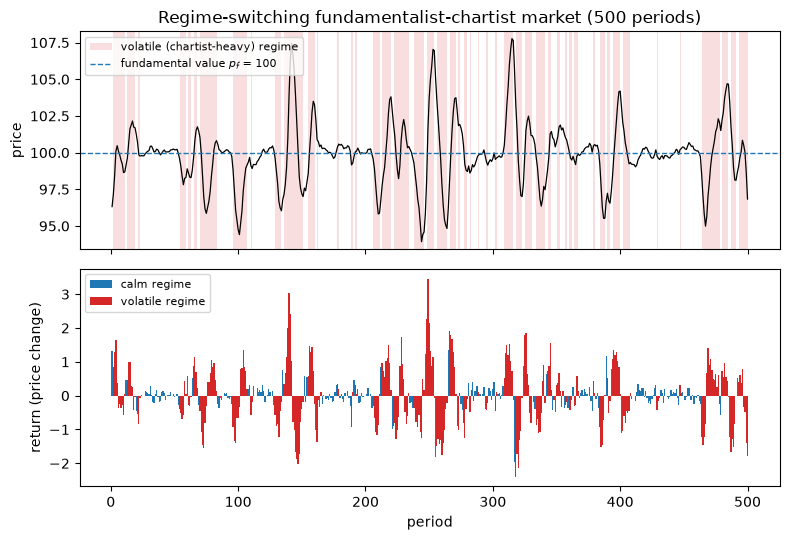

In [8]:
import matplotlib.pyplot as plt
# Section 20.2.1: the 500-period regime-switching simulation computed above
p20_t = np.arange(1, len(regimes) + 1)
p20_vol = regimes == 'volatile'
p20_fig, (p20_ax1, p20_ax2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
p20_ax1.plot(p20_t, prices[2:], color="black", lw=0.9)
p20_ax1.fill_between(p20_t, prices.min() - 0.5, prices.max() + 0.5, where=p20_vol, step="mid",
                     color="tab:red", alpha=0.15, lw=0, label="volatile (chartist-heavy) regime")
p20_ax1.axhline(p_f, color="tab:blue", ls="--", lw=1, label="fundamental value $p_f$ = 100")
p20_ax1.set_ylim(prices.min() - 0.5, prices.max() + 0.5)
p20_ax1.set_ylabel("price")
p20_ax1.set_title("Regime-switching fundamentalist-chartist market (500 periods)")
p20_ax1.legend(loc="upper left", fontsize=8)
p20_ax2.bar(p20_t[~p20_vol], returns_aligned[~p20_vol], width=1.0, color="tab:blue", label="calm regime")
p20_ax2.bar(p20_t[p20_vol], returns_aligned[p20_vol], width=1.0, color="tab:red", label="volatile regime")
p20_ax2.set_xlabel("period")
p20_ax2.set_ylabel("return (price change)")
p20_ax2.legend(loc="upper left", fontsize=8)
p20_fig.tight_layout()
plt.show()

## Worked Example 3: Eisenberg-Noe Contagion Cascade

Reproduces Section 20.2.3's three-bank chain: Bank A owes Bank B \$50, Bank B owes Bank C \$40, and the banks hold external assets of \$60, \$10 and \$5. The first cell is the baseline, where every bank pays in full and system net worth is \$75. The second cell applies a \$45 shock to Bank A's external assets; compare it with the chapter's cascade table: A can pay only \$15 of its \$50 and defaults, which leaves B with \$25 against its \$40 obligation, so B defaults too, a bank that suffered no shock of its own. The system-wide loss is exactly the \$45 shock, but it is redistributed along the chain.

In [9]:
# Baseline (no shock): A -> B $50, B -> C $40, C has no obligations
external_baseline = {'A': 60.0, 'B': 10.0, 'C': 5.0}
owed = {'A': 50.0, 'B': 40.0, 'C': 0.0}  # what each bank owes

def clear_chain(external):
    # Simple chain A->B->C: resolve in payment order
    resources_A = external['A']
    paid_A = min(resources_A, owed['A'])
    resources_B = external['B'] + paid_A
    paid_B = min(resources_B, owed['B'])
    resources_C = external['C'] + paid_B
    paid_C = min(resources_C, owed['C'])
    net_worth = {
        'A': resources_A - paid_A,
        'B': resources_B - paid_B,
        'C': resources_C - paid_C,
    }
    paid = {'A': paid_A, 'B': paid_B, 'C': paid_C}
    received = {'A': 0.0, 'B': paid_A, 'C': paid_B}
    return paid, received, net_worth

print('--- Baseline (no shock) ---')
paid, received, net_worth = clear_chain(external_baseline)
for bank in ['A', 'B', 'C']:
    print(f'{bank}: received={received[bank]:.2f}  paid={paid[bank]:.2f}  net worth={net_worth[bank]:.2f}')
print('Total system net worth:', sum(net_worth.values()))

--- Baseline (no shock) ---
A: received=0.00  paid=50.00  net worth=10.00
B: received=50.00  paid=40.00  net worth=20.00
C: received=40.00  paid=0.00  net worth=45.00
Total system net worth: 75.0


In [10]:
# Shock: A's external assets fall from $60 to $15 (a $45 loss)
external_shocked = {'A': 15.0, 'B': 10.0, 'C': 5.0}

print('--- After a $45 shock to Bank A\'s external assets ---')
paid, received, net_worth = clear_chain(external_shocked)
for bank in ['A', 'B', 'C']:
    default_flag = ' (DEFAULT)' if paid[bank] < owed[bank] else ''
    print(f'{bank}: received={received[bank]:.2f}  paid={paid[bank]:.2f} of {owed[bank]:.2f} owed{default_flag}  net worth={net_worth[bank]:.2f}')
print('Total system net worth:', sum(net_worth.values()))
print('Total system-wide loss:', 75.0 - sum(net_worth.values()))

--- After a $45 shock to Bank A's external assets ---
A: received=0.00  paid=15.00 of 50.00 owed (DEFAULT)  net worth=0.00
B: received=15.00  paid=25.00 of 40.00 owed (DEFAULT)  net worth=0.00
C: received=25.00  paid=0.00 of 0.00 owed  net worth=30.00
Total system net worth: 30.0
Total system-wide loss: 45.0


### Experiment

How large must a shock be before it topples a bank that was never hit? The cell below reruns the chain of Section 20.2.3 for any shock to Bank A's external assets and any cushion of external assets at Bank B. Change the two parameters at the top and re-run: with the defaults (a \$45 shock, \$10 at Bank B) it reproduces the chapter's cascade, in which A and B both default and the system loses \$45. The table shows the regimes: up to a \$10 shock nobody defaults, up to \$30 only A defaults, and beyond \$30 the default passes on to B. Raise Bank B's cushion and the second threshold moves up one for one, while the system-wide loss always equals the shock.

In [11]:
exp20_shock = 45.0      # loss on Bank A's $60 of external assets; try 25 or 55, then re-run
exp20_ext_B = 10.0      # Bank B's external assets (its own cushion); try 20 or 35, then re-run

def exp20_cascade(shock, ext_B):
    ext = {'A': 60.0 - shock, 'B': ext_B, 'C': 5.0}
    exp20_paid, _, exp20_nw = clear_chain(ext)       # Section 20.2.3's clearing function
    exp20_defaults = [b for b in ['A', 'B', 'C'] if exp20_paid[b] < owed[b]]
    exp20_loss = (60.0 + ext_B + 5.0) - sum(exp20_nw.values())   # loss against the no-shock baseline
    return exp20_paid, exp20_nw, exp20_defaults, exp20_loss

exp20_p, exp20_n, exp20_d, exp20_l = exp20_cascade(exp20_shock, exp20_ext_B)
print(f"Shock ${exp20_shock:.0f} to A, Bank B cushion ${exp20_ext_B:.0f}: "
      f"A pays {exp20_p['A']:.2f}, B pays {exp20_p['B']:.2f}; defaults: {', '.join(exp20_d) or 'none'}; "
      f"C's net worth {exp20_n['C']:.2f}; system-wide loss {exp20_l:.2f}")
print("(book, Section 20.2.3, $45 shock: A pays 15.00, B pays 25.00, A and B default, C's net worth 30.00, loss 45.00)")

print(f"\nshock   A pays   B pays   defaults   C net worth   system loss   (Bank B cushion ${exp20_ext_B:.0f})")
for exp20_s in (0, 10, 20, 30, 40, 45, 50, 60):
    exp20_row = exp20_cascade(float(exp20_s), exp20_ext_B)
    print(f"{exp20_s:>5}   {exp20_row[0]['A']:>6.2f}   {exp20_row[0]['B']:>6.2f}   {(','.join(exp20_row[2]) or '-'):>8}   "
          f"{exp20_row[1]['C']:>11.2f}   {exp20_row[3]:>11.2f}")

Shock $45 to A, Bank B cushion $10: A pays 15.00, B pays 25.00; defaults: A, B; C's net worth 30.00; system-wide loss 45.00
(book, Section 20.2.3, $45 shock: A pays 15.00, B pays 25.00, A and B default, C's net worth 30.00, loss 45.00)

shock   A pays   B pays   defaults   C net worth   system loss   (Bank B cushion $10)
    0    50.00    40.00          -         45.00          0.00
   10    50.00    40.00          -         45.00         10.00
   20    40.00    40.00          A         45.00         20.00
   30    30.00    40.00          A         45.00         30.00
   40    20.00    30.00        A,B         35.00         40.00
   45    15.00    25.00        A,B         30.00         45.00
   50    10.00    20.00        A,B         25.00         50.00
   60     0.00    10.00        A,B         15.00         60.00


## Advanced Topics: Chain versus Hub-and-Spoke Contagion

Reproduces Section 20.3.3: a hub bank H owes \$30 to each of three peripheral banks, holds \$100 of external assets, and takes the same \$45 shock as Bank A in the chain. Pro-rata Eisenberg-Noe clearing lets H pay 61.1% of its \$90 of obligations, so each peripheral receives \$18.33 instead of \$30 and its net worth falls from \$35 to \$23.33, a 33.3% loss. Look at the total: the system loses the same \$45 as in the chain, but the loss now lands on three banks at once rather than travelling down a line, which is why topology matters for contagion even when the aggregate loss does not change.

In [12]:
# Hub-and-spoke network: H owes $30 each to P1, P2, P3; same $45 shock as the chain example
owed_each = 30.0
n_peripherals = 3
total_owed = owed_each * n_peripherals
external_H_baseline = 100.0
external_Pi = 5.0

def clear_star(external_H):
    resources_H = external_H
    paid_H = min(resources_H, total_owed)
    net_H = resources_H - paid_H
    per_Pi_received = paid_H * (owed_each / total_owed)
    net_Pi = external_Pi + per_Pi_received
    total = net_H + n_peripherals * net_Pi
    return net_H, net_Pi, per_Pi_received, paid_H, total

print('--- Baseline ---')
net_H, net_Pi, per_Pi_received, paid_H, total = clear_star(external_H_baseline)
print(f'H: net worth={net_H:.2f}   Each P_i: net worth={net_Pi:.2f}   Total={total:.2f}')

print('--- After a $45 shock to H (external assets 100 -> 55) ---')
net_H_s, net_Pi_s, per_Pi_received_s, paid_H_s, total_s = clear_star(external_H_baseline - 45.0)
recovery = paid_H_s/total_owed*100
pct_loss_Pi = (net_Pi-net_Pi_s)/net_Pi*100
print(f'H: recovery={recovery:.1f}%  net worth={net_H_s:.2f} (DEFAULT)')
print(f'Each P_i: received={per_Pi_received_s:.2f}  net worth={net_Pi_s:.2f}  loss={pct_loss_Pi:.1f}%')
print(f'Total system net worth: {total_s:.2f}   Total loss: {total-total_s:.2f}')

--- Baseline ---
H: net worth=10.00   Each P_i: net worth=35.00   Total=115.00
--- After a $45 shock to H (external assets 100 -> 55) ---
H: recovery=61.1%  net worth=0.00 (DEFAULT)
Each P_i: received=18.33  net worth=23.33  loss=33.3%
Total system net worth: 70.00   Total loss: 45.00


### Stability Threshold Verification: n_c* = 1/(lambda*beta)

Checks the stability condition of Section 20.1.5: with $\lambda = 1.5$ and $\beta = 1.0$, the fundamentalist-chartist market is stable if and only if $\lambda n_c \beta < 1$, so the critical chartist share is $n_c^* = 1/(\lambda\beta) = 0.6667$. The cell simulates one population just below the threshold and one just above it. Look at the printed prices: at $n_c = 0.60$ they oscillate around 100 with shrinking amplitude and settle near 99.94 after 60 periods, while at $n_c = 0.70$ the swings grow (from 109.08 down to 88.2 within 15 periods). The plot after the cell adds the knife-edge case $n_c = n_c^*$.

In [13]:
p_f = 100.0
alpha, beta, lam = 0.3, 1.0, 1.5
nc_star = 1 / (lam * beta)
print('Theoretical critical threshold n_c* =', round(nc_star, 4))

def simulate_path(nc, steps):
    nf = 1 - nc
    p_prev2, p_prev = 93.0, 95.0
    path = [p_prev2, p_prev]
    for t in range(steps):
        d_f = alpha * (p_f - p_prev)
        d_c = beta * (p_prev - p_prev2)
        p_new = p_prev + lam * (nf * d_f + nc * d_c)
        p_prev2, p_prev = p_prev, p_new
        path.append(p_new)
    return path

print()
print('n_c = 0.60 (below threshold, should converge):')
path_below = simulate_path(0.60, 60)
print([round(path_below[i], 2) for i in [0, 10, 20, 30, 40, 50, 60]])

print()
print('n_c = 0.70 (above threshold, should diverge):')
path_above = simulate_path(0.70, 15)
print([round(path_above[i], 2) for i in range(0, 16, 3)])

Theoretical critical threshold n_c* = 0.6667

n_c = 0.60 (below threshold, should converge):
[93.0, 100.02, 102.43, 99.0, 99.56, 100.53, 99.94]

n_c = 0.70 (above threshold, should diverge):
[93.0, 100.99, 109.08, 107.85, 97.26, 88.2]


**Plot: three sides of the threshold.** The fundamentalist-chartist price path of the cell above for 40 periods at three chartist shares: just below the critical share (0.60), exactly at it ($n_c^* = 2/3$), and just above it (0.70). Below the threshold the oscillation dies out, at the threshold it neither grows nor shrinks, and above it every swing is larger than the last. Nothing in either trader type's rule mentions 2/3; the tipping point belongs to the population, not to any agent.

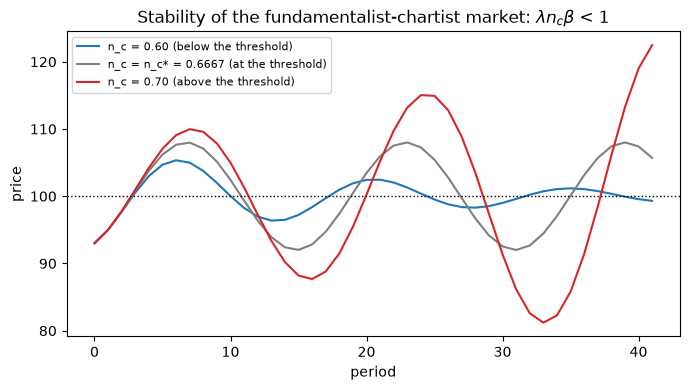

In [14]:
import matplotlib.pyplot as plt
# Section 20.1.5: price paths just below, at and just above the critical chartist share
p20_steps = 40
p20_fig, p20_ax = plt.subplots(figsize=(7, 4))
for p20_nc, p20_col, p20_lab in ((0.60, "tab:blue", "n_c = 0.60 (below the threshold)"),
                                 (nc_star, "gray", f"n_c = n_c* = {nc_star:.4f} (at the threshold)"),
                                 (0.70, "tab:red", "n_c = 0.70 (above the threshold)")):
    p20_ax.plot(np.arange(p20_steps + 2), simulate_path(p20_nc, p20_steps), color=p20_col, lw=1.5, label=p20_lab)
p20_ax.axhline(p_f, color="black", ls=":", lw=1)
p20_ax.set_xlabel("period")
p20_ax.set_ylabel("price")
p20_ax.set_title("Stability of the fundamentalist-chartist market: $\\lambda n_c \\beta$ < 1")
p20_ax.legend(loc="upper left", fontsize=8)
p20_fig.tight_layout()
plt.show()

## ABM versus MARL: A Learning Seller in the Double Auction

Reproduces Section 20.2.6's learning seller, who has a cost of \$40 and chooses each round between a high ask (\$58) and a low ask (\$47), facing buyers whose valuations are drawn from \$45, \$50, \$55, \$60 and \$65. The true expected profits are 7.2 for the high ask and 5.6 for the low one. The seller explores both arms twice (rounds 1 to 4) and then plays greedily on the running averages. Compare each round with the chapter's table: the high arm's running average swings between 6.00 and 10.80 as luck comes and goes and ends at 7.20, while the low arm, abandoned after two tries at an average of 3.50, is never tried again: the exploration problem of reinforcement learning in miniature.

In [15]:
import numpy as np
ls_rng = np.random.default_rng(11)

cost = 40.0
ask_high = 58.0
ask_low = 47.0
valuations = [45, 50, 55, 60, 65]

def true_ev(ask):
    trades = [v for v in valuations if v >= ask]
    p_trade = len(trades) / len(valuations)
    return p_trade * (ask - cost)

print('True E[profit] Arm H:', true_ev(ask_high))
print('True E[profit] Arm Lo:', true_ev(ask_low))

seq = [int(ls_rng.choice(valuations)) for _ in range(12)]
print('Buyer valuation sequence:', seq)

history = {'H': [], 'Lo': []}
arm_schedule_forced = ['H', 'Lo', 'H', 'Lo']

for i, v in enumerate(seq):
    if i < 4:
        arm = arm_schedule_forced[i]
    else:
        avgH = sum(history['H']) / len(history['H']) if history['H'] else float('-inf')
        avgLo = sum(history['Lo']) / len(history['Lo']) if history['Lo'] else float('-inf')
        arm = 'H' if avgH >= avgLo else 'Lo'
    ask = ask_high if arm == 'H' else ask_low
    profit = (ask - cost) if v >= ask else 0.0
    history[arm].append(profit)
    avgH_after = sum(history['H'])/len(history['H']) if history['H'] else float('nan')
    avgLo_after = sum(history['Lo'])/len(history['Lo']) if history['Lo'] else float('nan')
    print(f'Round {i+1:2d}: value={v}  arm={arm:2s}  profit={profit:5.1f}  avgH={avgH_after:5.2f}  avgLo={avgLo_after:5.2f}')

True E[profit] Arm H: 7.2
True E[profit] Arm Lo: 5.6000000000000005
Buyer valuation sequence: [45, 45, 60, 55, 55, 60, 60, 45, 55, 45, 55, 65]
Round  1: value=45  arm=H   profit=  0.0  avgH= 0.00  avgLo=  nan
Round  2: value=45  arm=Lo  profit=  0.0  avgH= 0.00  avgLo= 0.00
Round  3: value=60  arm=H   profit= 18.0  avgH= 9.00  avgLo= 0.00
Round  4: value=55  arm=Lo  profit=  7.0  avgH= 9.00  avgLo= 3.50
Round  5: value=55  arm=H   profit=  0.0  avgH= 6.00  avgLo= 3.50
Round  6: value=60  arm=H   profit= 18.0  avgH= 9.00  avgLo= 3.50
Round  7: value=60  arm=H   profit= 18.0  avgH=10.80  avgLo= 3.50
Round  8: value=45  arm=H   profit=  0.0  avgH= 9.00  avgLo= 3.50
Round  9: value=55  arm=H   profit=  0.0  avgH= 7.71  avgLo= 3.50
Round 10: value=45  arm=H   profit=  0.0  avgH= 6.75  avgLo= 3.50
Round 11: value=55  arm=H   profit=  0.0  avgH= 6.00  avgLo= 3.50
Round 12: value=65  arm=H   profit= 18.0  avgH= 7.20  avgLo= 3.50


## Method of Simulated Moments: Sweeping the Switching Threshold

Reproduces the threshold sweep of Section 20.3.1: the regime-switching simulation of Section 20.2.1 rerun at five switching thresholds, each with the same seed, recording the Pearson kurtosis of returns. Compare the printed values with the chapter's table (3.87, 3.61, 4.67, 7.43, 8.60). Kurtosis rises as the threshold rises, that is, as the volatile regime becomes harder to trigger, with one small dip between the two lowest thresholds that reflects the noise of a single 500-period run. Calibration by simulated moments picks the threshold whose simulated kurtosis matches the one measured in data.

In [16]:
import numpy as np
from scipy import stats

def run_sim(threshold, seed=42):
    msm_rng = np.random.default_rng(seed)
    p_f = 100.0
    alpha, beta_switch, lam_switch = 0.3, 1.1, 1.0
    nf_calm, nc_calm = 0.85, 0.15
    nf_vol, nc_vol = 0.25, 0.75
    sigma_calm, sigma_vol = 0.15, 0.50
    T = 500
    prices = [95.0, 95.0]
    for t in range(2, T + 2):
        p_prev, p_prev2 = prices[-1], prices[-2]
        recent = p_prev - p_prev2
        if abs(recent) > threshold:
            nf, nc, sigma_e = nf_vol, nc_vol, sigma_vol
        else:
            nf, nc, sigma_e = nf_calm, nc_calm, sigma_calm
        d_f = alpha * (p_f - p_prev)
        d_c = beta_switch * (p_prev - p_prev2)
        shock = msm_rng.normal(0, sigma_e)
        p_new = p_prev + lam_switch * (nf * d_f + nc * d_c) + shock
        prices.append(p_new)
    prices = np.array(prices)
    returns = np.diff(prices)
    return stats.kurtosis(returns, fisher=False)

for th in [0.15, 0.20, 0.25, 0.30, 0.35]:
    k = run_sim(th)
    print(f'threshold={th:.2f}  Pearson kurtosis={k:.3f}')

threshold=0.15  Pearson kurtosis=3.865
threshold=0.20  Pearson kurtosis=3.608
threshold=0.25  Pearson kurtosis=4.669
threshold=0.30  Pearson kurtosis=7.425
threshold=0.35  Pearson kurtosis=8.602
